In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from scipy.sparse import hstack

#NLP
import re
import nltk
import string
from nltk import sent_tokenize, word_tokenize
from nltk.tokenize.toktok import ToktokTokenizer
from bs4 import BeautifulSoup
import spacy
from nltk.stem import WordNetLemmatizer


In [3]:
df = pd.read_csv(r"train.csv")

In [4]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [5]:
df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [6]:
# Let's create another column "bad_comment" denoting any type of toxicity in the comment

df["bad_comment"] = df.iloc[:,2:].sum(axis = 1)
df["bad_comment"][df["bad_comment"] != 0] = 1
df.head(20)

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0,1
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0,0


In [7]:
train=df.sample(frac=0.7,random_state=42) #random state is a seed value
test=df.drop(train.index)
train_corpus = train['comment_text']
test_corpus = test['comment_text']

In [8]:
class_names = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate','bad_comment']

all_corpus = pd.concat([train_corpus, test_corpus])

In [9]:
# Word TF-IDF Vectorizer
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    stop_words='english',
    ngram_range=(1, 1),
    max_features=10000)
word_vectorizer.fit(all_corpus)
train_word_features = word_vectorizer.transform(train_corpus)
test_word_features = word_vectorizer.transform(test_corpus)

In [10]:
# Char TF-IDF Vectorizer
char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    stop_words='english',
    ngram_range=(2, 6),
    max_features=50000)
char_vectorizer.fit(all_corpus)
train_char_features = char_vectorizer.transform(train_corpus)
test_char_features = char_vectorizer.transform(test_corpus)

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\sklearn\feature_extraction\text.py:497: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn("The parameter 'stop_words' will not be used"


In [11]:
train_features = hstack([train_char_features, train_word_features])
test_features = hstack([test_char_features, test_word_features])

In [12]:
scores = []
submission = pd.DataFrame.from_dict({'id': test['id']})
submission_2 = pd.DataFrame.from_dict({'id': test['id']})
for class_name in class_names:
    train_target = train[class_name]
    classifier = LogisticRegression(C=0.1, solver='sag')

    cv_score = np.mean(cross_val_score(classifier, train_features, train_target, cv=5, scoring='roc_auc'))
    scores.append(cv_score)
    print('CV score for class {} is {}'.format(class_name, cv_score))

    classifier.fit(train_features, train_target)
    submission[class_name] = classifier.predict_proba(test_features)[:, 1]
    submission_2[class_name] = classifier.predict(test_features)

print('Total CV score is {}'.format(np.mean(scores)))

submission.to_csv('submission.csv', index=False)

CV score for class toxic is 0.9684599591147973
CV score for class severe_toxic is 0.9877915631699132
CV score for class obscene is 0.9844448365352292
CV score for class threat is 0.985255155692365
CV score for class insult is 0.9772511828725158
CV score for class identity_hate is 0.9727249621096675
CV score for class bad_comment is 0.9682410374147145
Total CV score is 0.9777383852727434


In [13]:
submission.head(10)

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
2,000113f07ec002fd,0.037209,0.002693,0.015809,0.001655,0.013748,0.003064,0.042100
5,00025465d4725e87,0.016968,0.003696,0.012002,0.002296,0.010454,0.004670,0.018810
9,00040093b2687caa,0.045093,0.005251,0.020832,0.002475,0.021878,0.007068,0.046056
10,0005300084f90edc,0.001564,0.001237,0.002450,0.001110,0.002102,0.001425,0.001784
11,00054a5e18b50dd4,0.087243,0.006575,0.031043,0.003038,0.031591,0.008040,0.087871
13,0006f16e4e9f292e,0.042513,0.002771,0.012932,0.002209,0.014613,0.003794,0.049097
15,00078f8ce7eb276d,0.086293,0.004999,0.028543,0.003032,0.030465,0.007702,0.092781
16,0007e25b2121310b,0.176758,0.007340,0.050551,0.003385,0.054211,0.008374,0.184484
18,0009801bd85e5806,0.022388,0.004216,0.011312,0.002060,0.012385,0.004429,0.023382
19,0009eaea3325de8c,0.064492,0.003940,0.025953,0.002586,0.030373,0.005879,0.075176


In [14]:
submission_2.sum()

id               000113f07ec002fd00025465d4725e8700040093b2687c...
toxic                                                         2337
severe_toxic                                                   126
obscene                                                       1385
threat                                                           0
insult                                                        1161
identity_hate                                                   33
bad_comment                                                   2482
dtype: object



 toxic comment classification metrics


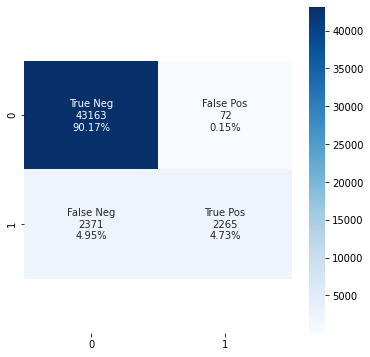

              precision    recall  f1-score   support

           0       0.95      1.00      0.97     43235
           1       0.97      0.49      0.65      4636

    accuracy                           0.95     47871
   macro avg       0.96      0.74      0.81     47871
weighted avg       0.95      0.95      0.94     47871



Accuracy=0.949
Precision=0.969
Recall=0.489
F1 Score=0.650


 severe_toxic comment classification metrics


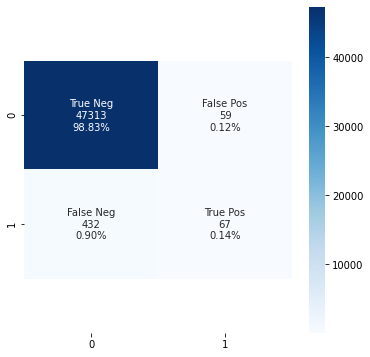

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     47372
           1       0.53      0.13      0.21       499

    accuracy                           0.99     47871
   macro avg       0.76      0.57      0.60     47871
weighted avg       0.99      0.99      0.99     47871



Accuracy=0.990
Precision=0.532
Recall=0.134
F1 Score=0.214


 obscene comment classification metrics


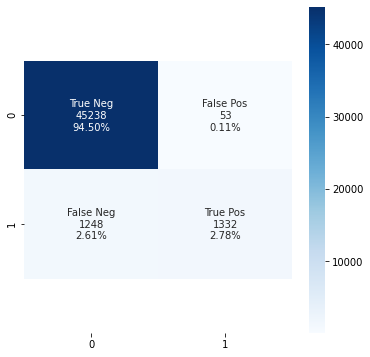

              precision    recall  f1-score   support

           0       0.97      1.00      0.99     45291
           1       0.96      0.52      0.67      2580

    accuracy                           0.97     47871
   macro avg       0.97      0.76      0.83     47871
weighted avg       0.97      0.97      0.97     47871



Accuracy=0.973
Precision=0.962
Recall=0.516
F1 Score=0.672


 threat comment classification metrics


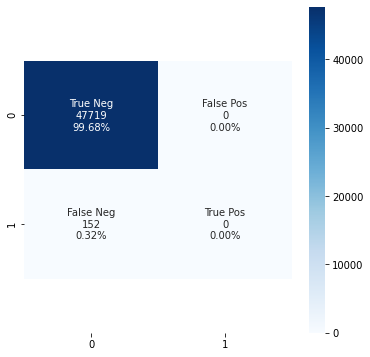

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\ipykernel_launcher.py:26: RuntimeWarning: invalid value encountered in longlong_scalars
C:\Users\Shivakrishna\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     47719
           1       0.00      0.00      0.00       152

    accuracy                           1.00     47871
   macro avg       0.50      0.50      0.50     47871
weighted avg       0.99      1.00      1.00     47871



Accuracy=0.997
Precision=nan
Recall=0.000
F1 Score=nan


 insult comment classification metrics


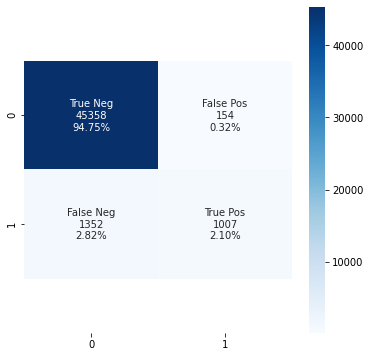

              precision    recall  f1-score   support

           0       0.97      1.00      0.98     45512
           1       0.87      0.43      0.57      2359

    accuracy                           0.97     47871
   macro avg       0.92      0.71      0.78     47871
weighted avg       0.97      0.97      0.96     47871



Accuracy=0.969
Precision=0.867
Recall=0.427
F1 Score=0.572


 identity_hate comment classification metrics


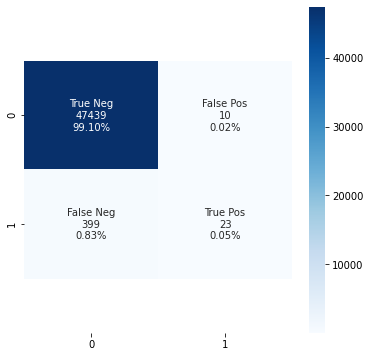

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     47449
           1       0.70      0.05      0.10       422

    accuracy                           0.99     47871
   macro avg       0.84      0.53      0.55     47871
weighted avg       0.99      0.99      0.99     47871



Accuracy=0.991
Precision=0.697
Recall=0.055
F1 Score=0.101


 bad_comment comment classification metrics


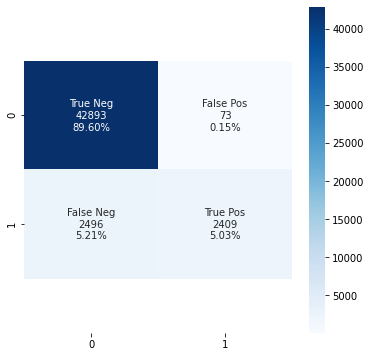

              precision    recall  f1-score   support

           0       0.95      1.00      0.97     42966
           1       0.97      0.49      0.65      4905

    accuracy                           0.95     47871
   macro avg       0.96      0.74      0.81     47871
weighted avg       0.95      0.95      0.94     47871



Accuracy=0.946
Precision=0.971
Recall=0.491
F1 Score=0.652


In [15]:
# Plotting Confusion Matrix

for class_name in class_names:
    
    print(f'\n\n {class_name} comment classification metrics')
    
    cf_matrix = confusion_matrix(test[class_name],submission_2[class_name])

    group_names = ['True Neg','False Pos','False Neg','True Pos']

    group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

    group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

    labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

    labels = np.asarray(labels).reshape(2,2)

    plt.figure(figsize=(6,6))
    ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
    bottom, top = ax.get_ylim()
    ax.set_ylim(bottom+0.5,top-0.5)
    plt.show()

    accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
    precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
    recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
    f1_score  = 2*precision*recall / (precision + recall)
    stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
    accuracy,precision,recall,f1_score)
    print(classification_report(test[class_name],submission_2[class_name]))
    print(stats_text)
    

# My Version

# Normalizing Comments

In [16]:
# removing html tags
def strip_html_tags(text):
    soup = BeautifulSoup(text,'html.parser')
    stripped_text = soup.get_text()
    return stripped_text

In [17]:
# removing accented characters
def remove_accented_chars(text):
    text = unicodedata.normalize('NFKD',text).encode('ascii','ignore').decode('utf-8','ignore')
    return text

!pip install contractions
from contractions import contractions_dict
# Expand contractions
def expand_contractions(text, contraction_mapping=contractions_dict):
    contractions_pattern = re.compile('({})'.format('|'.join(contraction_mapping.keys())),
                                      flags=re.IGNORECASE|re.DOTALL)
    
    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        expanded_contraction = contraction_mapping.get(match)\
                                if contraction_mapping.get(match)\
                                else contraction_mapping.get(match.lower())
        expanded_contraction = first_char + expanded_contraction[1:]
        return expanded_contraction
    
    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'","",expanded_text)
    return expanded_text

In [23]:
nlp = spacy.load('en_core_web_sm', parse=True, tag=True, entity=True)
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')

In [24]:
# Lemmatization
def lemmatize_text(text):
    text = nlp(text)
    text = ' '.join([word.lemma_ if word.lemma_ !='-PRON-' else word.text for word in text])
    return text

In [25]:
# Removing special characters
def remove_special_characters(text, remove_digits):
    pattern = r'[^a-zA-Z0-9\s]' if not remove_digits else r'[^a-zA-Z\s]'
    text = re.sub(pattern,'',text)
    return text

In [26]:
# Removing stopwords

def remove_stopwords(text, is_lower_case):
    tokens = tokenizer.tokenize(text)
    tokens = [token.strip() for token in tokens]
    if is_lower_case:
        filtered_tokens = [token for token in tokens if token not in stopword_list]
    else:
        filtered_tokens = [token for token in tokens if token.lower() not in stopword_list]
    filtered_text = ' '.join(filtered_tokens)
    return filtered_text

In [27]:
# Normalized corpus
def normalize_corpus(corpus,html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True):
    
    normalized_corpus = []
    try:
        for doc in corpus:
            # strip HTML
            if html_stripping:
                doc = strip_html_tags(doc)
            # remove accented characters
            if accented_char_removal:
                doc = remove_accented_chars(doc)
            # lowercase the text
            if text_lower_case:
                doc = doc.lower()
            # remove extra newlines
            doc = re.sub(r'[\r|\n\r\n]+','',doc)
            # lemmatize text
            if text_lemmatization:
                doc = lemmatize_text(doc)
            # remove special characters or digits
            if special_char_removal:
                # insert spaces between special character to isolate them
                special_char_pattern = re.compile(r'([{.(-)!}])')
                doc = special_char_pattern.sub(" \\1 ",doc)
                doc = remove_special_characters(doc, True)
            # remove extra whitespace
            doc = re.sub(' +', ' ', doc)
            # remove stopwords
            if stopword_removal:
                doc = remove_stopwords(doc, is_lower_case=text_lower_case)
        
            normalized_corpus.append(doc)
     
        return normalized_corpus 
    except:
        return normalized_corpus

In [28]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0


In [ ]:
%%time
norm_corpus = normalize_corpus(df['clean_comments'],html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True)

In [ ]:
#Build TF-IDF features on train articles
tv_1_2 = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0,ngram_range=(1,2),max_features=5000)
tv_1_2_train_features = tv_1_2.fit_transform(train_corpus)

# transform test articles into features
tv_1_2_test_features = tv_1_2.transform(test_corpus)

In [ ]:
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(tv_1_2_train_features, train_bad_comment)
svm_tv_pred =svm.predict(tv_1_2_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
plt.show()

print(classification_report(test_bad_comment,svm_tv_pred))

# With Upsampling

In [ ]:
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(up_tv_train_features, df_upsampled["bad_comment"])
up_svm_tv_pred =svm.predict(up_tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,up_svm_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
plt.show()


print(classification_report(test_bad_comment,up_svm_tv_pred))

C:\Users\Shivakrishna\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.
